this notebook creates the final Figure (Fig. 5)

<p>for heavy, kappa and lambda chains change: IMGT_FASTA and CHAIN
<p>change OUTPUT_DIR before running

In [1]:

from pathlib import Path
import re
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

/home/vsp/.local/lib/python3.9/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


no effect
Input study-event rows: 1125280
Study-position classifications: 225056
Final replicated charge-related classifications: 1260
Results written to: /home/vsp/Documents/groupmeetings/pictures
Reminder: within-study dependence cannot be corrected without clone/sequence data. The fold-change threshold and cross-study agreement are conservative filters, not a clone-aware statistical model.


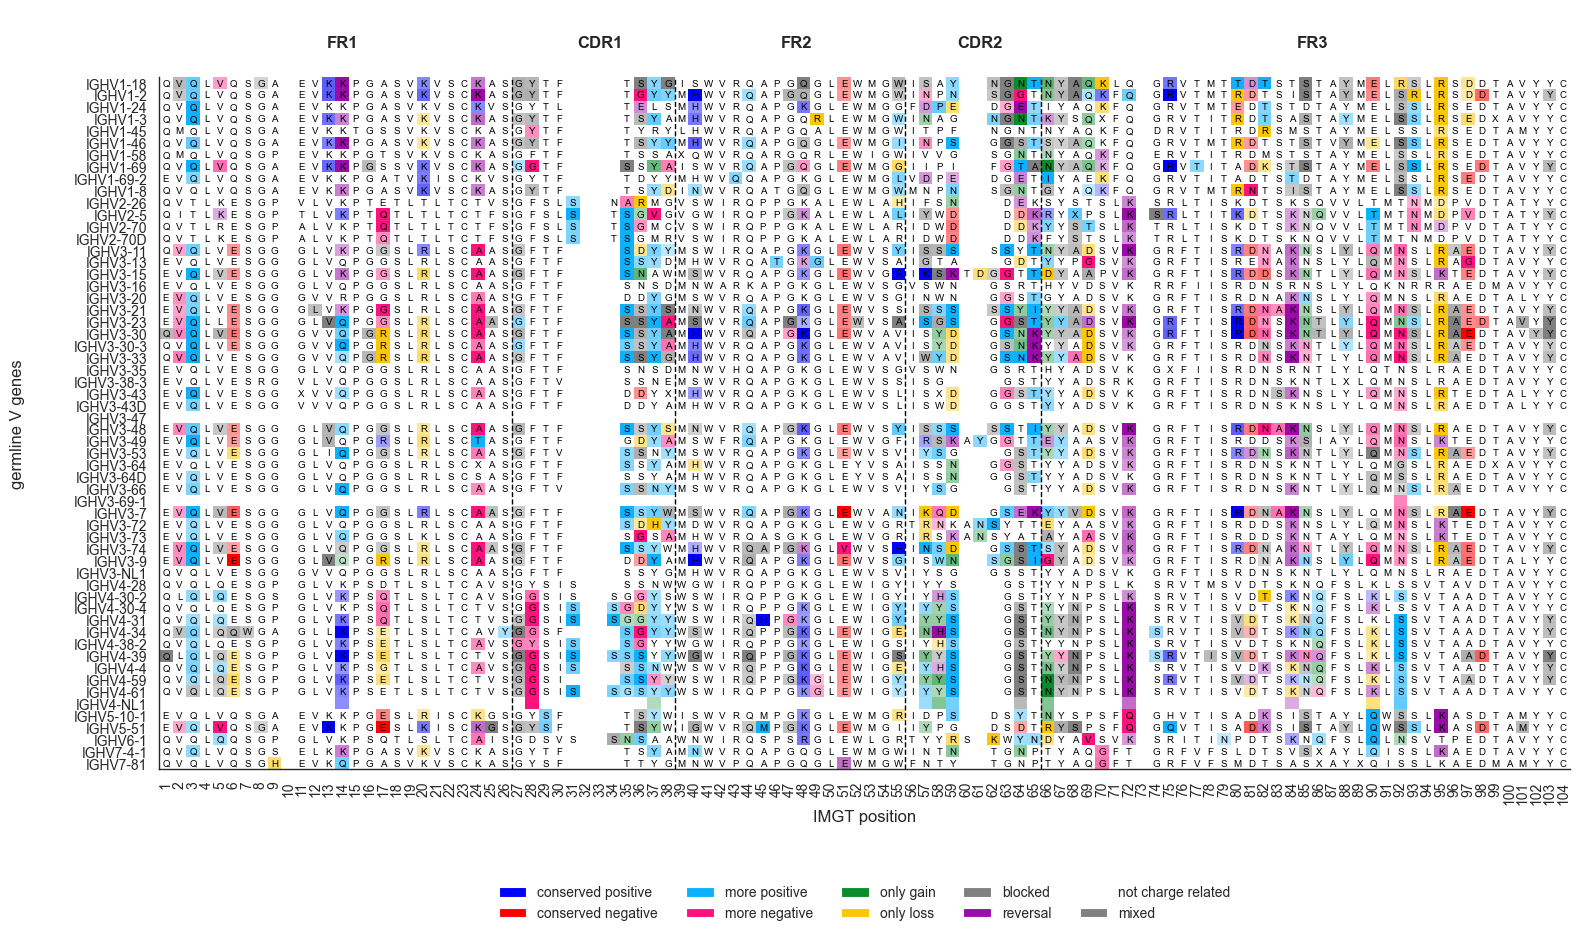

Saved plot: /home/vsp/Documents/groupmeetings/pictures/chargemutationselection_OE_heavy_vgenes.png


In [ ]:

"""
Conservative cross-study classification of charge-related SHM events.

Statistical design:
- A TSV is treated as one study-level aggregate.
- Each study contributes one class vote per V gene and position.
- Classes are retained only when there are enough studies and a dominant
  class meets the required agreement threshold.
"""

from pathlib import Path
import re
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# ============================================================================
# SETTINGS
# ============================================================================

ROOT = Path(
    "./by_vgene_project"
)
IMGT_FASTA = Path(
    "./IGHV_genes_imgt.fasta" #change to IGKV_genes_imgt.fasta and IGLV_genes_imgt.fasta
)
OUTPUT_DIR = Path(
    "FREE_TO_CHOOSE"
)
CHAIN = 'OE_heavy_' #change to OE_lambda_ and OE_kappa_

OUTPUT_PLOT = OUTPUT_DIR / f"chargemutationselection_{CHAIN}vgenes.png"

INPUT_FILENAME = "charge_OE_per_sequence_104_codons.tsv"



# An effect must exceed this fold-change to count as enriched/depleted.
# This is an explicit, tunable biological threshold, not a significance cutoff.
MIN_FOLD_CHANGE = 0.1
MIN_STUDIES = 3
MIN_AGREEMENT = 0.66

# Avoid interpreting unstable ratios where the expected count is tiny.
# Set to 0 to disable this filter.
MIN_EXPECTED_FOR_CLASSIFICATION = 0.005

FS = 12
FSS = 10

EVENT_ORDER = [
    "positive_gain",
    "negative_gain",
    "positive_loss",
    "negative_loss",
    "reversal",
]
EVENT_LABELS = {
    "positive_gain": "Positive charge gain",
    "negative_gain": "Negative charge gain",
    "positive_loss": "Positive charge loss",
    "negative_loss": "Negative charge loss",
    "reversal": "Charge reversal",
}
CLASS_ORDER = [
    "conserved positive",
    "conserved negative",
    "more positive",
    "more negative",
    "only gain",
    "only loss",
    "blocked",
    "reversal",
    "not charge related",
    "mixed",
]
CLASS_CODES = {name: i for i, name in enumerate(CLASS_ORDER)}
CLASS_COLORS = ["blue","red", "#0FB0FC","#FF127E", "#0A8C2B","#FCC609","grey", "#9A0CA8",  "white","grey"   ]
CHARGE_RELATED_CLASSES = {
    "conserved positive", "conserved negative", "more positive",
    "more negative", "only gain", "only loss", "blocked", "reversal",
}
IMGT_REGIONS = [
    ("FR1", 1, 26),
    ("CDR1", 27, 38),
    ("FR2", 39, 55),
    ("CDR2", 56, 65),
    ("FR3", 66, 104),
    ("CDR3", 105, 117),
]
IMGT_BOUNDARIES = [26.5, 38.5, 55.5, 65.5, 104.5]


# ============================================================================
# INPUT PARSING
# ============================================================================

def infer_gene_and_study(path: Path, root: Path):
    """Infer gene and study from path components such as OE_heavy_IGHV3-23_STUDY."""
    rel_parts = path.relative_to(root).parts[:-1]
    gene_dir = next((part for part in rel_parts if part.startswith(CHAIN)), None)
    if gene_dir is None:
        return None, None

    suffix = gene_dir[len(CHAIN):]
    
    tokens = suffix.split("_")
    gene = tokens[0]
    suffix_study = "_".join(tokens[1:]).strip("_")

    other_parts = [p for p in rel_parts if p != gene_dir]
    study_parts = other_parts + ([suffix_study] if suffix_study else [])
    study = "/".join(study_parts) if study_parts else path.stem
    return gene, study


def read_event_table(path: Path) -> pd.DataFrame:
    """Read the wide TSV and return one row per position and charge event."""
    raw = pd.read_csv(path, sep="\t")
    required = {"aa_position", "region", "coverage"}
    missing = required - set(raw.columns)
    if missing:
        raise ValueError(f"{path}: missing required columns: {sorted(missing)}")

    # Accept column names such as positive_gain_observed and
    # positive_gain_expected_targeting.
    pattern = re.compile(
        r"^(positive_gain|negative_gain|positive_loss|negative_loss|reversal)_(.+)$"
    )
    value_cols = [c for c in raw.columns if pattern.match(str(c))]
    if not value_cols:
        raise ValueError(f"{path}: no recognised event metric columns found")

    long = raw.melt(
        id_vars=["aa_position", "region", "coverage"],
        value_vars=value_cols,
        var_name="event_metric",
        value_name="value",
    )
    extracted = long["event_metric"].str.extract(pattern)
    long["event"] = extracted[0]
    long["metric"] = extracted[1]
    long = long.dropna(subset=["event"])

    long["value"] = pd.to_numeric(long["value"], errors="coerce")
    wide = long.pivot_table(
        index=["aa_position", "region", "coverage", "event"],
        columns="metric",
        values="value",
        aggfunc="first",
    ).reset_index()
    wide.columns.name = None
    
    for col in ("observed_frequency", "expected_frequency"):
        
        if col not in wide.columns:
            continue
        
        wide[col] = pd.to_numeric(wide[col], errors="coerce")

    wide["oe_ratio"] = np.where(
        wide["expected_frequency"] > 0,
        wide["observed_frequency"] / wide["expected_frequency"],
        np.nan,
    )
    wide["log2_oe"] = np.log2(wide["oe_ratio"].where(wide["oe_ratio"] > 0))
    wide["valid_effect"] = (
        np.isfinite(wide["observed_frequency"])
        & np.isfinite(wide["expected_frequency"])
        & (wide["observed_frequency"] >= 0)
        & (wide["expected_frequency"] >= MIN_EXPECTED_FOR_CLASSIFICATION)
    )
    return wide


# ============================================================================
# STUDY-LEVEL EFFECTS AND CLASSIFICATION
# ============================================================================

def make_event_flags(event_table: pd.DataFrame) -> pd.DataFrame:
    """
    Define enrichment/depletion using fold-change thresholds
    """
    df = event_table.copy()
    df["is_enriched"] = (
        df["valid_effect"]
        & (df["log2_oe"] >= MIN_FOLD_CHANGE)
    )
    df["is_depleted"] = (
        df["valid_effect"]
        & (df["log2_oe"] <= -MIN_FOLD_CHANGE)
    )
    return df


def classify_one_position(group: pd.DataFrame) -> str:
    """assign calss for each study × position."""
    flags = {}


    for event in EVENT_ORDER:
        rows = group.loc[group["event"] == event]
        flags[event + "_more"] = bool(rows["is_enriched"].any())
        flags[event + "_less"] = bool(rows["is_depleted"].any())

    pgm = flags["positive_gain_more"]
    ngm = flags["negative_gain_more"]
    plm = flags["positive_loss_more"]
    nlm = flags["negative_loss_more"]
    rm = flags["reversal_more"]

    pgl = flags["positive_gain_less"]
    ngl = flags["negative_gain_less"]
    pll = flags["positive_loss_less"]
    nll = flags["negative_loss_less"]
    rl = flags["reversal_less"]

    reversal = (pgm and nlm) or (ngm and plm) or rm
    if reversal:
        return "reversal"

    if pgm and not any([ngm, plm, nlm, rm]):
        return "more positive"

    if ngm and not any([pgm, plm, nlm, rm]):
        return "more negative"

    only_gain = (pgm or ngm) and not any([plm, nlm, rm])
    if only_gain:
        return "only gain"

    only_loss = (plm or nlm) and not any([pgm, ngm, rm])
    if only_loss:
        return "only loss"

    conserved_positive = (pll and not any([pgm, ngm, nlm, rm]))
    if conserved_positive:
        return "conserved positive"

    conserved_negative = (nll and not any([pgm, ngm, plm, rm]))
    if conserved_negative:
        return "conserved negative"

    blocked = (
        (pgl or ngl or rl)
        and not any([pgm, ngm, plm, nlm, rm])
    )
    if blocked:
        return "blocked"

    any_signal = any([
        pgm, ngm, plm, nlm, rm,
        pgl, ngl, pll, nll, rl,
    ])
    if not any_signal:
        # If some events could not be assessed because expected counts were
        # too low/missing, do not falsely call the position "not charge related".
        if not group["valid_effect"].all():
            
            return "mixed"
        return "not charge related"
    
    return "mixed"


def build_study_results(root: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    input_files = sorted(root.rglob(INPUT_FILENAME))
    if not input_files:
        raise FileNotFoundError(f"No {INPUT_FILENAME} files found below {root}")

    event_rows = []
    class_rows = []
    skipped = []

    for path in input_files:
        gene, study = infer_gene_and_study(path, root)
        if not gene:
            skipped.append(str(path))
            continue

        try:
            table = make_event_flags(read_event_table(path))
        except Exception as exc:
            
            continue

        table["gene"] = gene
        table["study"] = study
        table["source_file"] = str(path)
        event_rows.append(table)

        for position, group in table.groupby("aa_position", dropna=False):
            class_rows.append({
                "gene": gene,
                "study": study,
                "position": position,
                "class_label": classify_one_position(group),
                "source_file": str(path),
            })


    if not event_rows or not class_rows:
        raise ValueError("No usable study results found; check directory names and TSV columns.")

    return pd.concat(event_rows, ignore_index=True), pd.DataFrame(class_rows)


def summarise_cross_study(study_classes: pd.DataFrame):
    """Require independent-study replication and strong class agreement."""
    rows = []
    for (gene, position), group in study_classes.groupby(["gene", "position"]):
        # There should be one file per study/gene; deduplicate defensively.
        group = group.drop_duplicates(subset=["study"], keep="first")
        votes = group["class_label"].tolist()
        n_studies = len(votes)
        if n_studies < MIN_STUDIES:
            continue

        counts = Counter(votes)
        top_count = max(counts.values())
        winners = [label for label, count in counts.items() if count == top_count]
        if len(winners) != 1:
            continue

        winner = winners[0]
        agreement = top_count / n_studies
        if winner not in CHARGE_RELATED_CLASSES :
            continue

        rows.append({
            "gene": gene,
            "position": position,
            "class_label": winner,
            "n_studies": n_studies,
            "n_agree": top_count,
            "agreement": agreement,
            "caution": agreement < MIN_AGREEMENT,
            "study_votes": ";".join(votes),
        })

    return pd.DataFrame(rows, columns=[
        "gene", "position", "class_label", "n_studies", "n_agree",
        "agreement", "caution","study_votes",
    ])


# ============================================================================
# IMGT GERMLINE CONSENSUS
# ============================================================================

def read_imgt_alleles(fasta_path: Path):
    """Read IMGT alleles, excluding records matching the original filters."""
    alleles = defaultdict(list)
    if not fasta_path.exists():
        print(f"WARNING: IMGT FASTA not found at {fasta_path}; amino-acid overlay disabled.")
        return {}

    header, seq_parts = None, []

    def save_record(record_header, parts):
        if not record_header or not parts:
            return
        fields = record_header.split("|")
        if len(fields) < 14:
            return
        if fields[3] == "P" or fields[13].strip() != "":
            return
        allele_name = fields[1].strip()
        gene_name = allele_name.split("*")[0]
        sequence = re.sub(r"\s+", "", "".join(parts)).upper()
        
        alleles[gene_name].append((allele_name, sequence[:105]))

    with fasta_path.open() as handle:
        for line in handle:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                save_record(header, seq_parts)
                header, seq_parts = line[1:], []
            else:
                seq_parts.append(line)
        save_record(header, seq_parts)
    return dict(alleles)


def consensus_by_position(allele_records):
    if not allele_records:
        return {}
    sequences = [seq for _, seq in allele_records]
    lengths = {len(seq) for seq in sequences}
    if len(lengths) != 1:
        raise ValueError("IMGT alleles do not have equal aligned lengths; check FASTA alignment.")

    consensus = {}
    for col in range(len(sequences[0])):
        counts = Counter(
            seq[col] for seq in sequences
            if seq[col] not in {"-", ".", "X", "*", "?"}
        )
        if not counts:
            consensus[col] = " "
        else:
            max_count = max(counts.values())
            winners = [aa for aa, count in counts.items() if count == max_count]
            consensus[col] = winners[0] if len(winners) == 1 else "X"
    return consensus


# ============================================================================
# PLOT
# ============================================================================

def plot_classification(final_classes: pd.DataFrame, study_classes: pd.DataFrame):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    if final_classes.empty:
        print("No positions passed the cross-study consistency thresholds; no plot written.")
        return

    genes = sorted(study_classes["gene"].unique())
    positions = sorted(
        study_classes["position"].dropna().unique(),
        key=lambda value: float(value),
    )
    matrix = pd.DataFrame(np.nan, index=genes, columns=positions)

    for row in final_classes.itertuples(index=False):
        if row.gene in matrix.index and row.position in matrix.columns:
            matrix.loc[row.gene, row.position] = CLASS_CODES[row.class_label]

    class_cmap = ListedColormap(CLASS_COLORS)
    class_cmap.set_bad("white")

    alpha_matrix = np.ones(matrix.shape, dtype=float)
    for row in final_classes.itertuples(index=False):
        if row.gene in matrix.index and row.position in matrix.columns:
            if getattr(row, "caution", False) is True:
                i = matrix.index.get_loc(row.gene)
                j = matrix.columns.get_loc(row.position)
                value_agreement = getattr(row, "agreement")
                alpha_matrix[i, j] = value_agreement 
    sns.set_theme(style="white", context="paper")
    fig = plt.figure(figsize=(17, 10))
    grid = fig.add_gridspec(2, 1, height_ratios=[0.35, 4.0], hspace=0.02)
    ax_regions = fig.add_subplot(grid[0])
    ax_class = fig.add_subplot(grid[1])

    ax_class.imshow(
        np.ma.masked_invalid(matrix.to_numpy(dtype=float)),
        aspect="auto", cmap=class_cmap, vmin=-0.5,
        vmax=len(CLASS_ORDER) - 0.5, interpolation="nearest",alpha=alpha_matrix,
    )
    ax_class.set_yticks(np.arange(len(genes)))
    ax_class.set_yticklabels(genes, fontsize=FSS)
    ax_class.set_xticks(np.arange(len(positions)))
    ax_class.set_xticklabels(positions, rotation=90, fontsize=FSS)
    ax_class.set_xlabel("IMGT position", fontsize=FS)
    ax_class.set_ylabel("germline V genes", fontsize=FS, labelpad=35)

    imgt_alleles = read_imgt_alleles(IMGT_FASTA)
    gene_consensus = {
        gene: consensus_by_position(records)
        for gene, records in imgt_alleles.items()
    }
    
    for i, gene in enumerate(genes):
        consensus = gene_consensus.get(gene.split("*")[0])
        if consensus is None:
            print(f"WARNING: no IMGT alleles found for {gene}")
            continue
        for j, position in enumerate(positions):
            try:
                column = int(float(position)) - 1
            except (TypeError, ValueError):
                continue
            aa = consensus.get(column, "X")
            if aa not in {"-", ".", "*"}:
                ax_class.text(j, i, aa, ha="center", va="center",
                              fontsize=7, color="black", zorder=5)

    for spine in ax_class.spines.values():
        spine.set_visible(False)

    ax_regions.set_xlim(ax_class.get_xlim())
    ax_regions.set_ylim(0, 1)
    ax_regions.axis("off")
    numeric_positions = np.asarray(positions, dtype=float)
    for label, start, end in IMGT_REGIONS:
        indices = np.where((numeric_positions >= start) & (numeric_positions <= end))[0]
        if len(indices):
            ax_regions.text((indices[0] + indices[-1] + 1) / 2, 0.45, label,
                            ha="center", va="center", fontsize=FS, fontweight="bold")

    for boundary in IMGT_BOUNDARIES:
        idx = np.searchsorted(numeric_positions, boundary, side="right")
        if 0 < idx < len(numeric_positions):
            ax_class.axvline(idx - 0.5, color="black", linestyle="--",
                             linewidth=1.0, zorder=10)

    legend_handles = [
        Patch(facecolor=CLASS_COLORS[i], label=CLASS_ORDER[i])
        for i in range(len(CLASS_ORDER))
    ]
    ax_class.legend(handles=legend_handles, loc="upper center",
                    bbox_to_anchor=(0.5, -0.15), ncol=5,
                    frameon=False, fontsize=FSS)
    sns.despine(ax=ax_class, left=False, bottom=False)
    plt.subplots_adjust(left=0.15, right=0.98, top=0.96, bottom=0.20)
    fig.savefig(OUTPUT_PLOT, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved plot: {OUTPUT_PLOT}")


# ============================================================================
# MAIN
# ============================================================================

def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    event_results, study_classes = build_study_results(ROOT)
    final_classes = summarise_cross_study(study_classes)

    # Save study-level effect sizes so every final classification can be audited.
    event_results.to_csv(OUTPUT_DIR / f"study_event_effects_{CHAIN}.tsv", sep="\t", index=False)
    study_classes.to_csv(OUTPUT_DIR / f"study_position_classes_{CHAIN}.tsv", sep="\t", index=False)
    final_classes.to_csv(OUTPUT_DIR / f"final_consistent_position_classes_{CHAIN}.tsv", sep="\t", index=False)

    print(f"Input study-event rows: {len(event_results)}")
    print(f"Study-position classifications: {len(study_classes)}")
    print(f"Final replicated charge-related classifications: {len(final_classes)}")
    print(f"Results written to: {OUTPUT_DIR}")
    print(
        "Reminder: within-study dependence cannot be corrected without clone/sequence "
        "data. The fold-change threshold and cross-study agreement are conservative "
        "filters, not a clone-aware statistical model."
    )

    plot_classification(final_classes, study_classes)


if __name__ == "__main__":
    main()
